# PTB-XL multilabel raw-waveform SVM — GPU version

Uses all 12 leads and all waveform samples (typically 1,000 × 12 = 12,000 values per ECG). Training and inference use NVIDIA cuML's native GPU `SVC`; five binary SVMs are fitted explicitly (one-vs-rest).

**Environment:** Run this notebook in Ubuntu under WSL2, using a Python environment with compatible NVIDIA RAPIDS/cuML and CuPy installed. This notebook intentionally imports `cuml.svm.SVC` directly rather than relying on `cuml.accel`, so unsupported scikit-learn operations cannot silently make the SVM fall back to CPU.

For a CUDA 13 / RAPIDS 26.10 environment, install the matching cuML package in WSL2 (for example: `python -m pip install "cuml-cu13==26.10.*"`). Follow the RAPIDS installation selector if your CUDA/driver combination differs.

In [1]:
from pathlib import Path
import ast
import gc
import time

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import wfdb
from cuml.preprocessing import StandardScaler as cuStandardScaler
from cuml.svm import SVC as cuSVC
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
    multilabel_confusion_matrix,
)

# Confirm that CuPy can see an NVIDIA GPU before doing any expensive work.
try:
    gpu_count = cp.cuda.runtime.getDeviceCount()
    if gpu_count < 1:
        raise RuntimeError("No CUDA GPU was detected by CuPy.")
    gpu_name = cp.cuda.runtime.getDeviceProperties(0)["name"]
    if isinstance(gpu_name, bytes):
        gpu_name = gpu_name.decode("utf-8", errors="replace")
except Exception as exc:
    raise RuntimeError(
        "CUDA is not available to this Python environment. Run this notebook "
        "inside WSL2 Ubuntu with the Windows NVIDIA driver visible and CuPy/cuML installed."
    ) from exc

print(f"GPU detected: {gpu_name}")

# Automatically find the project root.
for p in [Path.cwd(), *Path.cwd().parents]:
    if (p / "data" / "ptb-xl").is_dir():
        PROJECT = p
        break
else:
    raise FileNotFoundError(
        "Could not find data/ptb-xl. Check that the project is accessible from WSL2 "
        "and that the notebook is running from within the project."
    )

DATA = next((PROJECT / "data" / "ptb-xl").rglob("ptbxl_database.csv")).parent
SCP_FILE = DATA / "scp_statements.csv"

CLASSES = ["NORM", "MI", "STTC", "CD", "HYP"]
N_LEADS = 12
print("Using dataset:", DATA)


GPU detected: NVIDIA GeForce RTX 5070 Ti
Using dataset: /mnt/c/Users/radun/Desktop/ecg-classification/data/ptb-xl


## Load labels, load complete ECG waveforms, and split the data

WFDB loading and label parsing happen on the CPU. The resulting waveform matrices are transferred to the GPU for scaling and SVM training. Each ECG is represented by every sample from all 12 leads; no hand-crafted statistical features are extracted.

Patient-level PTB-XL folds remain separate: folds 1–8 for training, 9 for validation, and 10 for testing.

In [2]:
print("test")

df = pd.read_csv(DATA / "ptbxl_database.csv")
df["scp_codes"] = df["scp_codes"].apply(ast.literal_eval)
scp = pd.read_csv(SCP_FILE, index_col=0)
scp = scp[scp["diagnostic"] == 1]

def make_labels(codes):
    found = {
        scp.at[code, "diagnostic_class"]
        for code in codes
        if code in scp.index and pd.notna(scp.at[code, "diagnostic_class"])
    }
    return [int(label in found) for label in CLASSES]

Y = np.asarray(df["scp_codes"].apply(make_labels).tolist(), dtype=np.uint8)

# Load complete waveforms. WFDB returns (time_samples, 12 leads).
waveforms = []
expected_shape = None

from tqdm.auto import tqdm

for filename in tqdm(df["filename_lr"], desc="Loading ECGs"):
    signal, _ = wfdb.rdsamp(str(DATA / filename))
    signal = np.asarray(signal, dtype=np.float32)

    if signal.ndim != 2 or signal.shape[1] != N_LEADS:
        raise ValueError(
            f"Expected a 2D ECG with {N_LEADS} leads, "
            f"but {filename} has shape {signal.shape}"
        )

    if expected_shape is None:
        expected_shape = signal.shape
    elif signal.shape != expected_shape:
        raise ValueError(
            f"Inconsistent ECG shape: {filename} has {signal.shape}; "
            f"expected {expected_shape}"
        )

    # One row per ECG; each lead's entire time series is kept contiguously.
    waveforms.append(signal.T.reshape(-1))

X = np.stack(waveforms).astype(np.float32, copy=False)
X = np.nan_to_num(X, nan=0.0, posinf=0.0, neginf=0.0)

fold = df["strat_fold"].to_numpy()
train_mask, val_mask, test_mask = fold <= 8, fold == 9, fold == 10

X_train, X_val, X_test = X[train_mask], X[val_mask], X[test_mask]
Y_train, Y_val, Y_test = Y[train_mask], Y[val_mask], Y[test_mask]

print("Original ECG shape (samples, leads):", expected_shape)
print("Raw waveform matrix:", X.shape)
print("Values per ECG:", X.shape[1])
print("Train / validation / test:", X_train.shape, X_val.shape, X_test.shape)
print("Training positives:", dict(zip(CLASSES, Y_train.sum(axis=0))))

# Fit the scaler on the training fold only, using GPU arrays throughout.
print("\nTransferring waveform splits to GPU and fitting cuML StandardScaler...")
X_train_gpu_raw = cp.asarray(X_train, dtype=cp.float32)
X_val_gpu_raw = cp.asarray(X_val, dtype=cp.float32)
X_test_gpu_raw = cp.asarray(X_test, dtype=cp.float32)

gpu_scaler = cuStandardScaler()
X_train_gpu = cp.asarray(gpu_scaler.fit_transform(X_train_gpu_raw), dtype=cp.float32)
X_val_gpu = cp.asarray(gpu_scaler.transform(X_val_gpu_raw), dtype=cp.float32)
X_test_gpu = cp.asarray(gpu_scaler.transform(X_test_gpu_raw), dtype=cp.float32)

# Release unscaled GPU copies; the CPU X arrays remain available if needed.
del X_train_gpu_raw, X_val_gpu_raw, X_test_gpu_raw
cp.get_default_memory_pool().free_all_blocks()
cp.cuda.Stream.null.synchronize()
print("GPU-scaled matrices:", X_train_gpu.shape, X_val_gpu.shape, X_test_gpu.shape)


test


/home/radun/miniforge3/envs/rapids-26.10/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading ECGs: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21799/21799 [03:00<00:00, 120.62it/s]


Original ECG shape (samples, leads): (1000, 12)
Raw waveform matrix: (21799, 12000)
Values per ECG: 12000
Train / validation / test: (17418, 12000) (2183, 12000) (2198, 12000)
Training positives: {'NORM': np.uint64(7596), 'MI': np.uint64(4379), 'STTC': np.uint64(4186), 'CD': np.uint64(3907), 'HYP': np.uint64(2119)}

Transferring waveform splits to GPU and fitting cuML StandardScaler...
GPU-scaled matrices: (17418, 12000) (2183, 12000) (2198, 12000)


## Tune the SVM on the validation fold (GPU)

cuML's native binary SVC is used directly. One-vs-rest is implemented as five independent binary GPU SVMs, one for each diagnostic superclass. This avoids depending on scikit-learn meta-estimator dispatch and makes each GPU fit explicit.

The scaler is fitted only on folds 1–8. Hyperparameters and the shared decision threshold are selected on fold 9. Fold 10 is reserved for final evaluation.

In [6]:
C_VALUES = [
    1, 2, 4, 8, 16, 32, 64, 128
]

GAMMA_VALUES = [
    0.00002,
    0.00005,
    0.00008,
    0.0001,
    0.0002,
    0.0003,
    0.0005,
    0.0008,
    0.001,
]

THRESHOLDS = [
    -0.5, -0.25, 0, 0.1, 0.25, 0.5, 0.75
]

# Train one binary cuML SVC at a time and return validation decision scores.
# This keeps temporary GPU memory use lower than fitting all five in parallel.
def fit_ovr_and_score(X_fit_gpu, y_fit, X_score_gpu, C, gamma):
    scores = np.empty((X_score_gpu.shape[0], len(CLASSES)), dtype=np.float32)

    for class_idx, class_name in enumerate(CLASSES):
        y_binary_gpu = cp.asarray(y_fit[:, class_idx], dtype=cp.int32)
        classifier = cuSVC(
            kernel="rbf",
            C=float(C),
            gamma=gamma,
            class_weight="balanced",
            cache_size=1024.0,
            output_type="cupy",
        )
        classifier.fit(X_fit_gpu, y_binary_gpu)
        class_scores_gpu = classifier.decision_function(X_score_gpu)
        scores[:, class_idx] = cp.asnumpy(class_scores_gpu).reshape(-1)
        del classifier, y_binary_gpu, class_scores_gpu

    cp.cuda.Stream.null.synchronize()
    gc.collect()
    return scores

best_score = -np.inf
best_params = None
best_threshold = None

total_start = time.perf_counter()

for C in C_VALUES:
    for gamma in GAMMA_VALUES:
        run_start = time.perf_counter()

        val_scores = fit_ovr_and_score(
            X_train_gpu, Y_train, X_val_gpu, C=C, gamma=gamma
        )

        config_best_score = -np.inf
        config_best_threshold = None

        for threshold in THRESHOLDS:
            val_predictions = (val_scores >= threshold).astype(np.uint8)
            val_macro_f1 = f1_score(
                Y_val, val_predictions, average="macro", zero_division=0
            )

            if val_macro_f1 > config_best_score:
                config_best_score = val_macro_f1
                config_best_threshold = threshold

        if config_best_score > best_score:
            best_score = config_best_score
            best_params = {"C": C, "gamma": gamma}
            best_threshold = config_best_threshold

        run_time = time.perf_counter() - run_start
        print(
            f"C={C}, gamma={gamma}: "
            f"best validation macro F1={config_best_score:.4f} "
            f"(threshold={config_best_threshold}) | "
            f"time={run_time:.2f}s"
        )
        del val_scores

        # CuPy synchronizes above so timings include completed GPU work.
        cp.get_default_memory_pool().free_all_blocks()

# Refit only the selected configuration and retain the five GPU models.
def fit_ovr_models(X_fit_gpu, y_fit, C, gamma):
    models = []
    for class_idx, class_name in enumerate(CLASSES):
        y_binary_gpu = cp.asarray(y_fit[:, class_idx], dtype=cp.int32)
        classifier = cuSVC(
            kernel="rbf",
            C=float(C),
            gamma=gamma,
            class_weight="balanced",
            cache_size=1024.0,
            output_type="cupy",
        )
        classifier.fit(X_fit_gpu, y_binary_gpu)
        models.append(classifier)
        print(f"Trained GPU SVC for {class_name}")
        del y_binary_gpu
    cp.cuda.Stream.null.synchronize()
    return models

def ovr_decision_scores(models, X_gpu):
    scores = np.empty((X_gpu.shape[0], len(models)), dtype=np.float32)
    for class_idx, classifier in enumerate(models):
        scores[:, class_idx] = cp.asnumpy(
            classifier.decision_function(X_gpu)
        ).reshape(-1)
    return scores

total_time = time.perf_counter() - total_start
print("\nBest parameters:", best_params)
print("Best threshold:", best_threshold)
print(f"Best validation macro F1: {best_score:.4f}")
print(f"Hyperparameter search time: {total_time:.2f}s")

print("\nRefitting the selected five-model one-vs-rest SVM on the GPU...")
best_models = fit_ovr_models(
    X_train_gpu, Y_train, C=best_params["C"], gamma=best_params["gamma"]
)


C=1, gamma=2e-05: best validation macro F1=0.4379 (threshold=-0.5) | time=2.97s
C=1, gamma=5e-05: best validation macro F1=0.4715 (threshold=-0.25) | time=3.04s
C=1, gamma=8e-05: best validation macro F1=0.4833 (threshold=-0.25) | time=3.15s
C=1, gamma=0.0001: best validation macro F1=0.4937 (threshold=-0.25) | time=3.49s
C=1, gamma=0.0002: best validation macro F1=0.5019 (threshold=-0.5) | time=4.09s
C=1, gamma=0.0003: best validation macro F1=0.4820 (threshold=-0.5) | time=4.62s
C=1, gamma=0.0005: best validation macro F1=0.3788 (threshold=-0.5) | time=5.12s
C=1, gamma=0.0008: best validation macro F1=0.1972 (threshold=-0.5) | time=5.84s
C=1, gamma=0.001: best validation macro F1=0.1821 (threshold=-0.5) | time=5.94s
C=2, gamma=2e-05: best validation macro F1=0.4391 (threshold=-0.5) | time=3.12s
C=2, gamma=5e-05: best validation macro F1=0.4747 (threshold=-0.5) | time=3.71s
C=2, gamma=8e-05: best validation macro F1=0.4952 (threshold=-0.5) | time=4.05s
C=2, gamma=0.0001: best validati

## Final test evaluation (GPU inference)

The five selected cuML SVC models calculate test decision scores on the GPU. Scores are copied to CPU memory only for thresholding, sklearn metric calculations, and plotting. The threshold was selected on validation fold 9.

Selected parameters: {'C': 4, 'gamma': 0.0002}
Selected threshold: -0.5
Test macro F1: 0.4956
              precision    recall  f1-score   support

        NORM       0.53      0.97      0.68       963
          MI       0.37      0.69      0.48       550
        STTC       0.35      0.74      0.47       521
          CD       0.33      0.69      0.45       496
         HYP       0.32      0.53      0.39       262

   micro avg       0.41      0.78      0.53      2792
   macro avg       0.38      0.72      0.50      2792
weighted avg       0.41      0.78      0.54      2792
 samples avg       0.47      0.78      0.56      2792



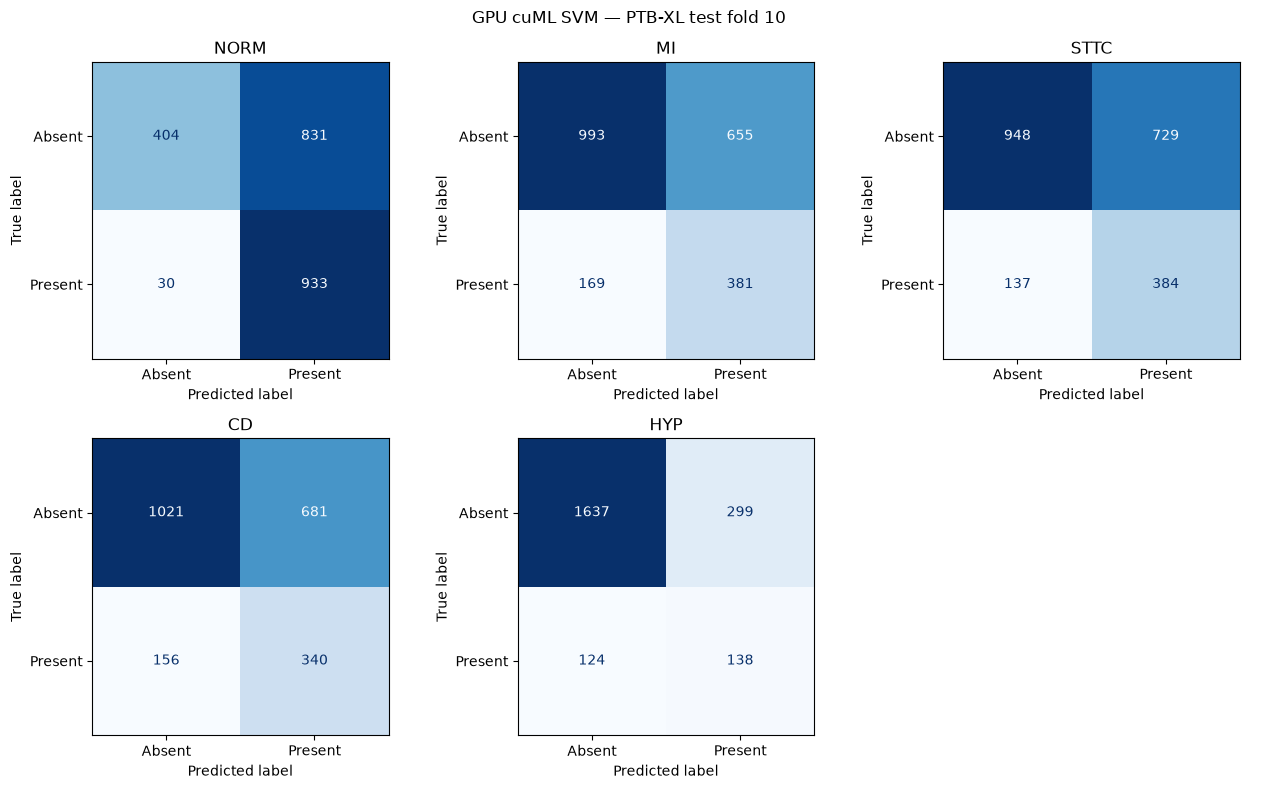

In [4]:
# Compute decision scores with the five GPU-trained cuML SVCs.
test_scores = ovr_decision_scores(best_models, X_test_gpu)
test_predictions = (test_scores >= best_threshold).astype(np.uint8)

print("Selected parameters:", best_params)
print("Selected threshold:", best_threshold)
print("Test macro F1:", round(
    f1_score(Y_test, test_predictions, average="macro", zero_division=0), 4
))
print(classification_report(
    Y_test, test_predictions, target_names=CLASSES, zero_division=0
))

confusion_matrices = multilabel_confusion_matrix(Y_test, test_predictions)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, class_name, matrix in zip(axes.flat, CLASSES, confusion_matrices):
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Absent", "Present"],
    ).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(class_name)

axes.flat[-1].axis("off")
fig.suptitle("GPU cuML SVM — PTB-XL test fold 10")
plt.tight_layout()
plt.show()
